------------------------------------------------------------
AT MONTH 60 (Total Forest Size: 625 trees)
Final symptomatic trees (No Control): 232 trees
Final symptomatic trees (Discrete p=0.3): 85 trees
------------------------------------------------------------


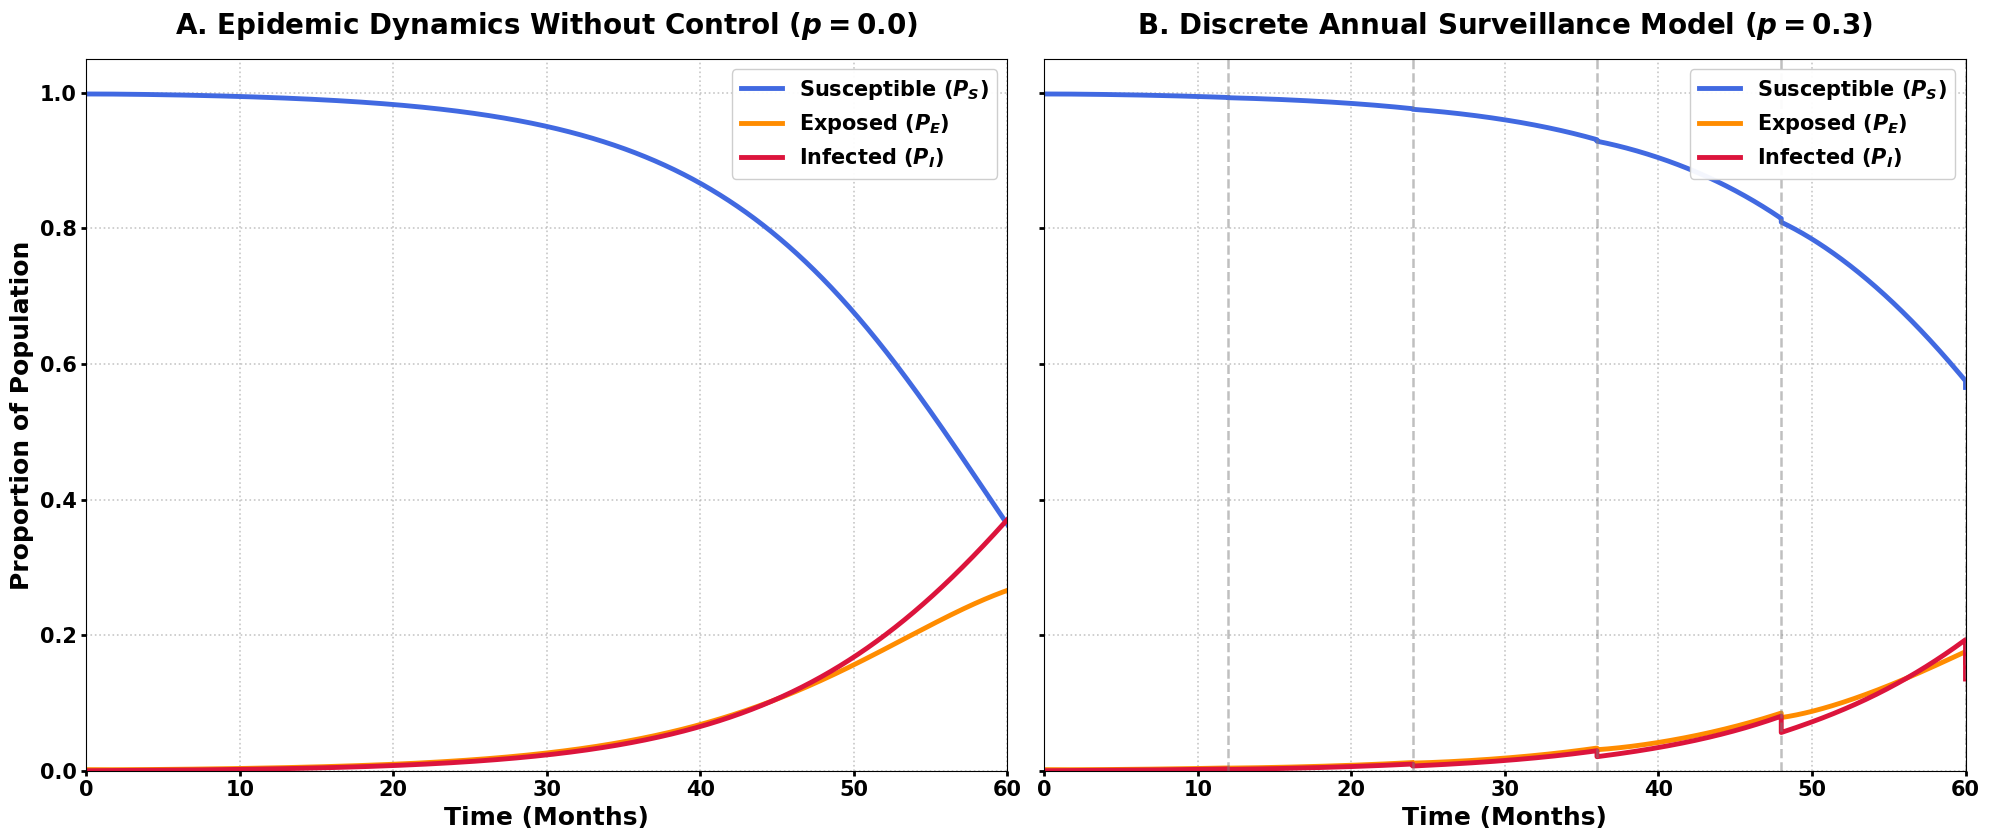

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ─── Core Parameters ─────────────────────────────────────────────────────────
beta = 0.82              # Transmission rate
rho  = 1.0 / 10.53       # 1 / Latent period (months)
L    = 0.99              # Degree of spatial localization (99% local spread)
N    = 625               # Population size

t_total         = 60     # Total simulation time (months)
survey_interval = 12     # Frequency of survey (every 12 months)
n_surveys       = t_total // survey_interval
steps_per_chunk = 500    # Numerical resolution per year

# Fixed detection probability
p_fixed = 0.3            

# Initial conditions
PE_init  = 1.0 / N
PS_init  = 1.0 - PE_init
PI_init  = 0.0

# State vector tracking: [PS, PE, PI, PSS, PSE, PSI, PEE, PEI]
y0_state = [
    PS_init, PE_init, PI_init,
    PS_init**2, PS_init * PE_init, 0.0,
    PE_init**2, 0.0
]

# ─── Free-Running SEI Pair Approximation ODEs ────────────────────────────────
def sei_free(t, y, beta, rho, L):
    PS, PE, PI, PSS, PSE, PSI, PEE, PEI = y

    qIS = PSI / PS if PS > 1e-12 else 0.0

    inf_S  = (1 - L) * PI + L * qIS
    inf_SS = (1 - L) * PI + 0.75 * L * qIS
    inf_SI = (1 - L) * PI + 0.25 * L + 0.75 * L * qIS

    dPS  = -beta * PS * inf_S
    dPE  =  beta * PS * inf_S - rho * PE
    dPI  =  rho * PE

    dPSS = -2 * beta * PSS * inf_SS
    dPSE =  beta * PSS * inf_SS - beta * PSE * inf_SS - rho * PSE
    dPSI =  rho * PSE - beta * PSI * inf_SI
    dPEE =  2 * beta * PSE * inf_SS - 2 * rho * PEE
    dPEI =  rho * PEE + beta * PSI * inf_SI - rho * PEI

    return [dPS, dPE, dPI, dPSS, dPSE, dPSI, dPEE, dPEI]

# ─── Discrete Survey State Transition (Algorithm 1) ─────────────────────────
def apply_discrete_survey(state, p):
    PS, PE, PI, PSS, PSE, PSI, PEE, PEI = state

    # Fractional removal (Roguing + Buffer Zone Clearance)
    detected_I = p * PI
    removed_S  = p * PSI
    removed_E  = p * PEI

    PS_new = max(PS - removed_S,  0.0)
    PE_new = max(PE - removed_E,  0.0) 
    PI_new = max(PI - detected_I, 0.0)

    # Scaling pairs proportionally
    fS = PS_new / PS if PS > 1e-12 else 0.0
    fE = PE_new / PE if PE > 1e-12 else 0.0
    fI = PI_new / PI if PI > 1e-12 else 0.0

    new_state = [
        PS_new, PE_new, PI_new,
        max(PSS * fS * fS, 0.0),
        max(PSE * fS * fE, 0.0),
        max(PSI * fS * fI, 0.0),
        max(PEE * fE * fE, 0.0),
        max(PEI * fE * fI, 0.0)
    ]
    return new_state

# ─── Simulation Engine ───────────────────────────────────────────────────────
def run_discrete(p_detection):
    state = y0_state.copy()
    t_now = 0.0

    all_t, all_PS, all_PE, all_PI = [], [], [], []

    for _ in range(n_surveys):

        t_chunk = np.linspace(
            t_now,
            t_now + survey_interval,
            steps_per_chunk
        )

        sol = solve_ivp(
            sei_free,
            [t_now, t_now + survey_interval],
            state,
            args=(beta, rho, L),
            t_eval=t_chunk,
            method='Radau',
            rtol=1e-8,
            atol=1e-10
        )

        all_t.append(sol.t)
        all_PS.append(sol.y[0])
        all_PE.append(sol.y[1])
        all_PI.append(sol.y[2])

        state_end = [sol.y[i][-1] for i in range(8)]
        state_after = apply_discrete_survey(state_end, p_detection)

        # Sharp vertical survey jumps
        survey_t = t_now + survey_interval

        all_t.append(np.array([survey_t, survey_t]))
        all_PS.append(np.array([state_end[0], state_after[0]]))
        all_PE.append(np.array([state_end[1], state_after[1]]))
        all_PI.append(np.array([state_end[2], state_after[2]]))

        state = state_after
        t_now += survey_interval

    return (
        np.concatenate(all_t),
        np.concatenate(all_PS),
        np.concatenate(all_PE),
        np.concatenate(all_PI)
    )

# ─── Run Simulations ─────────────────────────────────────────────────────────
# No control baseline
t_nc, PS_nc, PE_nc, PI_nc = run_discrete(p_detection=0.0)

# Discrete annual intervention
t_ds, PS_ds, PE_ds, PI_ds = run_discrete(p_detection=p_fixed)

# ─── CALCULATE AND PRINT FINAL NUMBERS ───────────────────────────────────────
final_infected_nc = int(round(PI_nc[-1] * N))
final_infected_ds = int(round(PI_ds[-1] * N))

print("-" * 60)
print(f"AT MONTH 60 (Total Forest Size: {N} trees)")
print(f"Final symptomatic trees (No Control): {final_infected_nc} trees")
print(f"Final symptomatic trees (Discrete p=0.3): {final_infected_ds} trees")
print("-" * 60)

# ─── GLOBAL STYLE SETTINGS ───────────────────────────────────────────────────
plt.rcParams.update({
    'font.weight': 'bold',
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold'
})

# ─── Multi-Panel Plotting Layout ─────────────────────────────────────────────
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 8.5),
    sharey=True
)

# High-visibility formatting
title_fs  = 20
label_fs  = 18
tick_fs   = 15
legend_fs = 15
lw        = 3.5

colors = {
    'S': 'royalblue',
    'E': 'darkorange',
    'I': 'crimson'
}

# ─── PANEL A: No Control Dynamics ────────────────────────────────────────────
axes[0].plot(
    t_nc, PS_nc,
    color=colors['S'],
    linewidth=lw,
    label='Susceptible ($P_S$)'
)

axes[0].plot(
    t_nc, PE_nc,
    color=colors['E'],
    linewidth=lw,
    label='Exposed ($P_E$)'
)

axes[0].plot(
    t_nc, PI_nc,
    color=colors['I'],
    linewidth=lw,
    label='Infected ($P_I$)'
)

axes[0].set_title(
    'A. Epidemic Dynamics Without Control ($p = 0.0$)',
    fontsize=title_fs,
    pad=18,
    fontweight='bold'
)

axes[0].set_xlabel(
    'Time (Months)',
    fontsize=label_fs,
    fontweight='bold'
)

axes[0].set_ylabel(
    'Proportion of Population',
    fontsize=label_fs,
    fontweight='bold'
)

axes[0].set_xlim([0, t_total])
axes[0].set_ylim([0, 1.05])

axes[0].grid(
    True,
    linestyle=':',
    linewidth=1.2,
    alpha=0.7
)

axes[0].legend(
    loc='upper right',
    fontsize=legend_fs,
    framealpha=0.95
)

axes[0].tick_params(
    axis='both',
    labelsize=tick_fs,
    width=2
)

# ─── PANEL B: Discrete Surveillance Model ────────────────────────────────────
axes[1].plot(
    t_ds, PS_ds,
    color=colors['S'],
    linewidth=lw,
    label='Susceptible ($P_S$)'
)

axes[1].plot(
    t_ds, PE_ds,
    color=colors['E'],
    linewidth=lw,
    label='Exposed ($P_E$)'
)

axes[1].plot(
    t_ds, PI_ds,
    color=colors['I'],
    linewidth=lw,
    label='Infected ($P_I$)'
)

# Survey indicator lines
for year in range(survey_interval, t_total + 1, survey_interval):

    axes[1].axvline(
        x=year,
        color='gray',
        linestyle='--',
        linewidth=1.8,
        alpha=0.5
    )

axes[1].set_title(
    f'B. Discrete Annual Surveillance Model ($p = {p_fixed}$)',
    fontsize=title_fs,
    pad=18,
    fontweight='bold'
)

axes[1].set_xlabel(
    'Time (Months)',
    fontsize=label_fs,
    fontweight='bold'
)

axes[1].set_xlim([0, t_total])
axes[1].set_ylim([0, 1.05])

axes[1].grid(
    True,
    linestyle=':',
    linewidth=1.2,
    alpha=0.7
)

axes[1].legend(
    loc='upper right',
    fontsize=legend_fs,
    framealpha=0.95
)

axes[1].tick_params(
    axis='both',
    labelsize=tick_fs,
    width=2
)

# ─── Final Layout ────────────────────────────────────────────────────────────
plt.tight_layout()

# High-resolution export
plt.savefig(
    'Discrete_Surveillance_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()